### Petrophysical joint inversion 

Parmeters are mainly defined in the the corresponding profile_settings file located at pji/profile_settings/.

All rights reserved. Material from GEOFCAN 2025 Workshop led by Coline Mollaret

In [ ]:
import time 
t = time.time() # get current time to check the time to run the script

In [1]:
#############################################
import sys, os
from pathlib import Path
# try and except functions to change the directory only once to stay in the right folder even the script/cell is run again
try:  
    findpaths
except NameError:  
    #sys.path.insert(0, os.path.abspath("..")) # to find "fpinv" in the main folder
    os.chdir(os.path.abspath("..")) #to find the folder where the data are stored
    findpaths=True
print('current working directory: ', os.getcwd()) #print the current working directory
#############################################


current working directory:  /home/jovyan/work/4pm-pji


In [2]:
# import python packages
#############################################
from sys import path
from fpinv import JointMod
import numpy as np
import pygimli as pg
from pygimli.physics import Refraction, ERTManager
from pygimli.physics.traveltime import createGradientModel2D
from pygimli.physics import ert
from datetime import datetime
from fpinv import JointInv, add_inner_title, rst_cov, minmax, FourPhaseModel, FourPhaseModelSomerton
import pandas as pd

fs=11

In [3]:
### Choose PROFILE ###################################################################
#profile='CH_COR_V01_2007-07-13_01' # change name of your profile 
#profile='CH_DOL_V01_2016-08-11_01'
#profile = 'KG_ABR_P03_2021-08-22_01'
profile='CH_LAP_MH1_2010-08-24_01'
#profile='3L'

print("profile: " + profile)

metadata_filename = 'inv_results_metadata.csv' # to keep track for run PJI parameters and results


profile: CH_LAP_MH1_2010-08-24_01


In [4]:
#############################################
# Import profile specific settings if they exist, otherwise import standard settings:
if os.path.exists(os.path.abspath('profile_settings/'+profile+'_settings.py')):
    exec(open('profile_settings/'+profile+'_settings.py', 'r').read()) # reads site specific settings
    print('profile settings exist and were loaded')
else:
    from settings import *
    print('profile settings do not exist, default was loaded') 

##### Creates new directories if not existing yet
Path(os.getcwd()+'/results/joint_inversion/').mkdir(parents=True, exist_ok=True)

profile settings exist and were loaded


In [5]:
### Load meshes ############################################
############################################################
mesh = pg.load('results/mesh/' + profile + '_mesh.bms')
paraDomain = pg.load('results/mesh/' + profile +"_paraDomain.bms")

A stands for Archie
G stands for the Geometric mean model (also named after Somerton)

the variable **equa** can be chosen in the corresponding profile_settings file. 

**equa** defines the petrophysical equation used to link the electrical resistivity with the paramters (i.e. the 4 phases)

The porosity constraints can be changed in the profile_settings file if wished.

In [6]:

print("resistivity equation: "+ equa)

print("min porosity: "+ str(poro_min))
print("start porosity: "+ str(poro))
print("max porosity: "+ str(poro_max))

# Poro to rock content (inversion parameters)
fr_min = 1 - poro_max
fr_max = 1 - poro_min

# Definition of the petrophysical model to use in the petrophysical joint inversion
if equa == 'G':
    fpm = FourPhaseModelSomerton(phi=poro, rhow=rhow, rhoi=rhoi, rhoa=rhoa, rhor=rhor, vr=vr) 
    print('Petropyhsical model chosen: Geometric mean model \n')
    print("\nrhow = "+str(rhow)+"\nrhoi = "+str(rhoi)+"\nrhoa = "+str(rhoa)+"\nrhor = "+str(rhor)+"\n")
elif equa== 'A':
    fpm = FourPhaseModel(vw=vw, vi=vi, va=va, vr=vr, phi=poro, n=n, m=m, a=a, rhow=rhow)
    print("Petropyhsical model chosen: Archie's law \n")
else:
    fpm = FourPhaseModel(vw=vw, vi=vi, va=va, vr=vr, phi=poro, n=n, m=m, a=a, rhow=rhow)
    print('\n', "WARNING Archie's law used by default! You need to define the variable equa.")

resistivity equation: A
min porosity: 0.2
start porosity: 0.4
max porosity: 0.7
Petropyhsical model chosen: Archie's law 



In [7]:
###### Preparation for the pji ###########################################
##########################################################################

# Load ERT data 
###########################################################################
ertScheme = pg.DataContainerERT('results/filtered_data/' + profile + "_ert_filtered.data")
ertScheme['k'] = ert.createGeometricFactors(ertScheme, numerical=True)

#############################################################################
# Setup managers and equip with meshes
ert = ERTManager()
ert.setMesh(mesh)
ert.setData(ertScheme)
ert.fop.createRefinedForwardMesh()

# Load RST data 
###########################################################################
ttData = pg.DataContainer('results/filtered_data/' + profile + "_rst_filtered.data", "s g")
rst = Refraction()
rst.setMesh(paraDomain)
rst.setData(ttData)
rst.fop.createRefinedForwardMesh()

# Set errors
ttData.set("err", np.ones(ttData.size()) * rste)
ertScheme.set("err", np.ones(ertScheme.size()) * erte)
###########################################################################

fixcells = False

13/10/25 - 10:48:31 - pyGIMLi - INFO - Cache /opt/conda/lib/python3.10/site-packages/pygimli/physics/ert/ert.py:createGeometricFactors restored (1.1s x 2): /home/jovyan/.cache/pygimli/4479681560088247646
13/10/25 - 10:48:31 - pyGIMLi - INFO - Found 2 regions.
13/10/25 - 10:48:31 - pyGIMLi - INFO - (ERTModelling) Region with smallest marker (1) set to background.
13/10/25 - 10:48:31 - Core - INFO - Create H2 refined mesh for forward tasks.
13/10/25 - 10:48:31 - pyGIMLi - INFO - Found 1 regions.
13/10/25 - 10:48:31 - Core - INFO - Create H2 refined mesh for forward tasks.


In [8]:
################################################################################
# Setup joint modeling and inverse operators 

JM = JointMod(paraDomain, ert, rst, fpm, fix_poro=False, zWeight=zWeight,
              fix_ice=fixcells, verbose = True) ## Gives error, ask Coline if ok?

# Put both datasets in manager
data = pg.cat(ttData("t"), ertScheme("rhoa"))

if weighting:
    n_rst = ttData.size()
    n_ert = ertScheme.size()
    avg = (n_rst + n_ert) / 2
    weight_rst = avg / n_rst
    weight_ert = avg / n_ert
else:
    weight_rst = 1
    weight_ert = 1

error = pg.cat(
    ttData("err") / ttData("t") / weight_rst,
    ertScheme("err") / weight_ert)

# Compute min an max rock matrix content from the given porosity range
fr_min = 1 - poro_max
fr_max = 1 - poro_min

# if not defined in the settings file, default values are used (defined below)
try: vTop  
except NameError: vTop = 300  
try: vBottom  
except NameError: vBottom = 6000 

# Start model
phi = np.ones(paraDomain.cellCount()) * poro

velstart = 1 / createGradientModel2D(ttData, paraDomain, vTop, vBottom)
rhostart = np.ones_like(velstart) * np.mean(ertScheme("rhoa"))
fas, fis, fws, _ = fpm.all(rhostart, velstart)
frs = np.ones_like(fas) - fpm.phi
frs[frs <= fr_min] = fr_min + 0.01
frs[frs >= fr_max] = fr_max - 0.01
if fixcells is not False:
    fis[fixcells] = 0.0
startmodel = np.concatenate((fws, fis, fas, frs))

# Fix small values to avoid problems in first iteration
startmodel[startmodel <= 0.001] = 0.001


13/10/25 - 10:48:31 - pyGIMLi - INFO - Using smoothing with zWeight = 0.25.
13/10/25 - 10:48:31 - Core - ERROR - ./core/src/regionManager.cpp:850		void GIMLI::RegionManager::fillConstraintWeights(GIMLI::RVector&)  in use??


### Run the Joint Inversion

You can ignore the following Error message : Core - ERROR - no cWeights defined. You should create constraints matrix first.

In [9]:

inv = JointInv(JM, data, error, startmodel, lam=lam, beta=beta, fwmin=fw_min, fwmax=fw_max, fimin=fi_min, fimax=fi_max, famin=fa_min, famax=fa_max, frmin=fr_min, frmax=fr_max, maxIter=maxIter)

#############################################################################
# Run inversion
#tic()
model = inv.run()
#print(toc())
print(("Chi squared fit:", inv.getChi2()))

# compute and show rhoa and tt individual chi2
#ertchi, ertrms = JM.ERTchi2(model, error)
#rstchi, rrstrms, absrmstt =JM.RSTchi2(model, error, ttData("t"))

#print("\n\nChi2 overall: \t%.2f; Rel rms: \t%.2f%%; \nChi2 ERT: \t%.2f; ERT rms: \t%.2f%%; \nChi2 RST: \t%.2f; RST rms: \t%.5f s    %.2f%%;\n\n" %(inv.chi2(), inv.relrms(), ertchi, ertrms*100, rstchi, rrstrms, absrmstt*100))


13/10/25 - 10:48:31 - pyGIMLi - INFO - Using smoothing with zWeight = 0.25.
13/10/25 - 10:48:31 - Core - ERROR - ./core/src/regionManager.cpp:850		void GIMLI::RegionManager::fillConstraintWeights(GIMLI::RVector&)  in use??
13/10/25 - 10:48:31 - pyGIMLi - INFO - Creating forward mesh from region infos.


min/max(dweight) = 33.3333/1000
model 0.001 1.5564517102394673
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
+                                 Iteration #0                                 +
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


13/10/25 - 10:48:31 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.
13/10/25 - 10:48:31 - pyGIMLi - INFO - Creating forward mesh from region infos.
13/10/25 - 10:48:31 - pyGIMLi - INFO - Creating refined mesh (H2) to solve forward task.
13/10/25 - 10:48:31 - pyGIMLi - INFO - Mesh for forward task: Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458


Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.11 | 0.11
 Ice:   0.00 | 0.34
 Air:   0.00 | 1.56
 Rock:  0.60 | 0.60
------------------------------
 SUM:   1.00 | 2.27
 Rho:   9.77e+03 | 9.77e+03
 Vel:   186 | 3852


13/10/25 - 10:49:04 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


...

 found valid constraints matrix. omit rebuild
constraint matrix of size(nBounds x nModel) 6824 x 4752
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.58
 Ice:   0.01 | 0.42
 Air:   0.00 | 0.55
 Rock:  0.31 | 0.66
------------------------------
 SUM:   0.84 | 1.32
 Rho:   2.49e+02 | 2.94e+05
 Vel:   502 | 4044
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.04 | 0.39
 Ice:   0.00 | 0.49
 Air:   0.00 | 0.56
 Rock:  0.31 | 0.69
------------------------------
 SUM:   0.88 | 1.21
 Rho:   4.17e+02 | 1.25e+05
 Vel:   505 | 3914
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.49
 Ice:   0.00 | 0.42
 Air:   0.00 | 0.54
 Rock

13/10/25 - 10:49:21 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


 found valid constraints matrix. omit rebuild
constraint matrix of size(nBounds x nModel) 6824 x 4752
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.01 | 0.38
 Ice:   0.01 | 0.75
 Air:   0.00 | 0.54
 Rock:  0.32 | 0.72
------------------------------
 SUM:   0.92 | 1.31
 Rho:   7.47e+02 | 2.88e+06
 Vel:   518 | 3883
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.49
 Ice:   0.00 | 0.42
 Air:   0.00 | 0.54
 Rock:  0.31 | 0.66
------------------------------
 SUM:   0.93 | 1.21
 Rho:   3.52e+02 | 1.93e+05
 Vel:   506 | 3999
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.42
 Ice:   0.00 | 0.48
 Air:   0.00 | 0.54
 Rock

13/10/25 - 10:49:25 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


 found valid constraints matrix. omit rebuild
constraint matrix of size(nBounds x nModel) 6824 x 4752
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.38
 Ice:   0.01 | 0.57
 Air:   0.00 | 0.54
 Rock:  0.31 | 0.66
------------------------------
 SUM:   0.99 | 1.26
 Rho:   7.11e+02 | 2.20e+05
 Vel:   518 | 3866
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.42
 Ice:   0.00 | 0.48
 Air:   0.00 | 0.54
 Rock:  0.31 | 0.67
------------------------------
 SUM:   0.96 | 1.16
 Rho:   5.30e+02 | 1.87e+05
 Vel:   512 | 3953
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.38
 Ice:   0.01 | 0.49
 Air:   0.00 | 0.54
 Rock

In [10]:
# Save estimated contents of the 4 pahses results
fwe, fie, fae, fre = JM.fractions(model)
fsum = fwe + fie + fae + fre

print("Min/Max sum of 4 phases:", round(min(fsum), 2), round(max(fsum),2))

# Compute back the "transformed" resistivity and velocity tomogram (through the 4PM equations).
rhoest = JM.fpm.rho(fwe, fie, fae, fre)
velest = 1. / JM.fpm.slowness(fwe, fie, fae, fre)

array_mask = np.array(((fae < 0) | (fae > 1 - fre))
                      | ((fie < 0) | (fie > 1 - fre))
                      | ((fwe < 0) | (fwe > 1 - fre))
                      | ((fre < 0) | (fre > 1))
                      | (fsum > 1.01))



Min/Max sum of 4 phases: 0.96 1.13


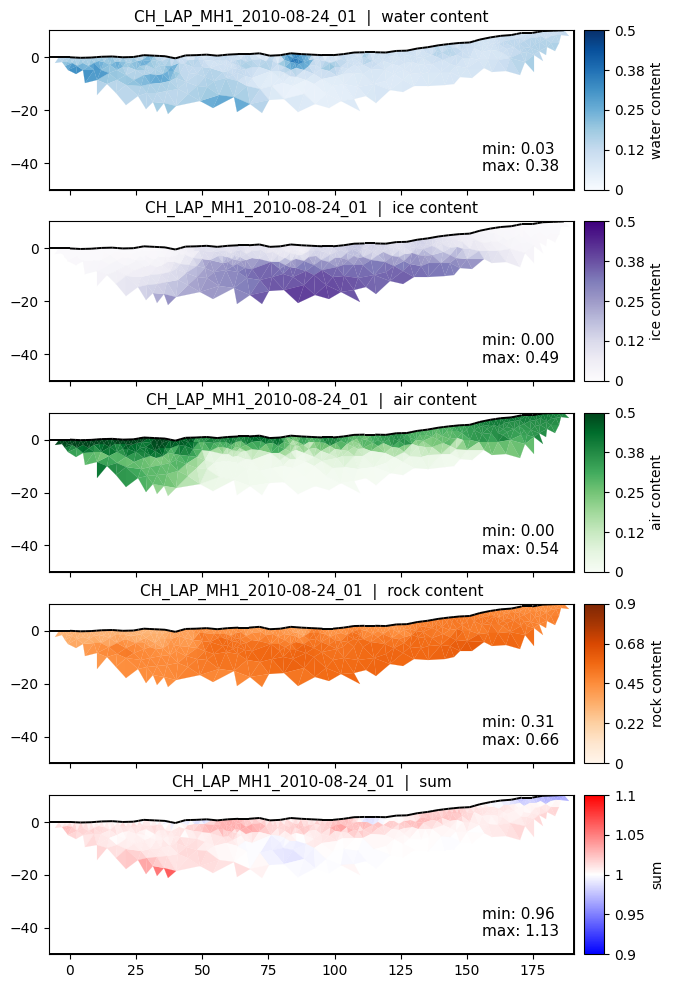

In [11]:
# load coverage
cov = rst_cov(paraDomain, np.loadtxt('results/rst_process/'+profile + "_rst_coverage.dat"))

# Plot the PJI results
fig, ax = pg.plt.subplots(5,sharex=True,figsize=(12,12))

rst.showResult(fwe,ax[0],cMin=cMinw, cMax=cMaxw, logScale=False, cMap=cMapw, label="water content", orientation="vertical", coverage=cov)
ax[0].set_title(profile + '  |  water content', fontsize=fs)
add_inner_title(ax[0], minmax(fwe), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fie,ax[1],cMin=cMini, cMax=cMaxi, logScale=False, cMap=cMapi, label="ice content", orientation="vertical", coverage=cov)
ax[1].set_title(profile + '  |  ice content', fontsize=fs)
add_inner_title(ax[1], minmax(fie), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fae,ax[2],cMin=cMina, cMax=cMaxa, logScale=False, cMap=cMapa, label="air content", orientation="vertical", coverage=cov)
ax[2].set_title(profile + '  |  air content', fontsize=fs)
add_inner_title(ax[2], minmax(fae), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fre,ax[3],cMin=cMinr, cMax=cMaxr, logScale=False, cMap=cMapr, label="rock content", orientation="vertical", coverage=cov)
ax[3].set_title(profile + '  |  rock content', fontsize=fs)
add_inner_title(ax[3], minmax(fre), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

rst.showResult(fsum,ax[4],cMin=0.9, cMax=1.1, logScale=False, cMap='bwr', label="sum", orientation="vertical", coverage=cov)
ax[4].set_title(profile + '  |  sum', fontsize=fs)
add_inner_title(ax[4], minmax(fsum), borderpad=1, loc=4, size=fs, fw="regular", frame=True)

pg.plt.savefig('results/joint_inversion/'+profile+'_PJI_'+equa+'.png', dpi=80)

In [12]:

###########################################################################
# Save results
if equa=='A':  # Archie
    np.savez('results/joint_inversion/' + profile + "_joint_inversion_A.npz" , vel=np.array(velest),
          rho=np.array(rhoest), fa=fae, fi=fie, fw=fwe, fr=fre, mask=array_mask)
if equa=='G':  # Geoetric mean model
    np.savez('results/joint_inversion/' + profile + "_joint_inversion_G.npz" , vel=np.array(velest), rho=np.array(rhoest), fa=fae, fi=fie, fw=fwe, fr=fre, mask=array_mask)
    np.savez('results/joint_inversion/' + profile + "_joint_inversion_"+equa+"_rhow"+str(rhow)+"_rhoi"+str(rhoi)+"_rhoa"+str(rhoa)+"_rhor"+str(rhor)+"_poro_"+str(poro_min)+"_"+str(poro)+"_"+str(poro_max)+".npz" , vel=np.array(velest), rho=np.array(rhoest), fa=fae, fi=fie, fw=fwe, fr=fre, mask=array_mask)
    np.savez('results/joint_inversion/' + profile + "_joint_inversion_"+equa+"_rhow"+str(rhow)+"_rhoi"+str(rhoi)+"_rhoa"+str(rhoa)+"_rhor"+str(rhor)+"_poro_"+str(poro_min)+"_"+str(poro)+"_"+str(poro_max)+"_chi2_"+str(round(inv.getChi2(),1))+"_rms_"+str(round(inv.relrms(),1))+".npz" , vel=np.array(velest), rho=np.array(rhoest), fa=fae, fi=fie, fw=fwe, fr=fre, mask=array_mask)
    
np.savez('results/joint_inversion/' + profile + "_joint_inversion.npz" , vel=np.array(velest),
          rho=np.array(rhoest), fa=fae, fi=fie, fw=fwe, fr=fre, mask=array_mask)
#Show results
##########################################################################
ertchi, ertrms = JM.ERTchi2(model, error)
rstchi, rstrms, absrmstt = JM.RSTchi2(model, error, ttData("t"))

print("#" * 80)
print("Overall chi^2 = %.2f   rms = %.2f" %( inv.getChi2(), inv.relrms() ) )
print("#" * 80)
print("\nERT chi^2 = %.2f   rms = %.2f%%" %( ertchi, ertrms*100) )
print( "\nRST chi^2 = %.2f   rms = %.5f ms / %.2f%%" %( rstchi, rstrms*1000, absrmstt*100) )
print("#" * 80)



###########################################################################
# datetime object containing current date and time
now = datetime.now()

# dd/mm/YY H:M:S
date_string = now.strftime("%d/%m/%Y %H:%M:%S")
print("date and time =", date_string)

# Write individual rms errors in settings.py 
path=os.getcwd()
fileW = path+'/profile_settings/'+profile+"_settings.py"
print(fileW)
f = open(fileW, 'a')
f.write("\n\njoint_inv_chi2 = %.2f \njoint_inv_rms = %.2f" %( inv.getChi2(), inv.relrms()) )
f.write("\njoint_ert_chi2 = %.2f \njoint_ert_rms = %.2f" %( ertchi, ertrms*100 ))
f.write("\njoint_rst_chi2 = %.2f \njoint_rst_rms = %.2f" %( rstchi, absrmstt*100) )
f.write("  # %s\n" %(date_string))
f.close()

###########################################################################################
# %% Save inversion parameters, Chi2, RMS to csv
# Get chi2 and rms errors from inversion
chi2_pji = inv.getChi2()
rms_pji = inv.relrms()

# Round error up to 2 decimals
chi2_pji = np.round(chi2_pji,2)
rms_pji = np.round(rms_pji,2)

# SAVE PJI RESULTS ONLY if chi2 is lower than 10. --> can be deleted!
'''
if chi2_pji <= 10:
    
    np.savez(profile + '_' + equa + '_' + 'chi2_' + str(chi2_pji) +'_' + 'rms_' + str(rms_pji) + "_joint_inversion.npz", 
             vel=np.array(velest),
              rho=np.array(rhoest), fa=fae, fi=fie, fw=fwe, fr=fre, mask=array_mask)
else: 
    print('PJI result not saved, error too large')

'''

# Save metadata to a CSV file
# Create a DataFrame using a dictionary of values
metadata_dict = {
    'Profile': [profile],
    'equation': [equa],           
    'chi2_pji': [chi2_pji],
    'rms_pji': [rms_pji],
    #'iterations': [len(inv.chi2History)], AttributeError: 'JointInv' object has no attribute 'chi2History'
    'rhoi': [rhoi],
    'rhoa': [rhoa],
    'rhor': [rhor],  
    'rhow': [rhow], 
    'lam': [lam],  
    'zWeight': [zWeight],  
    'beta': [beta],  
    'poro': [poro],  
    'fr_min': [np.round(fr_min,2)], 
    'fr_max': [fr_max], 
    'fw_min': [fw_min], 
    'fw_max': [fw_max], 
    'fi_min': [fi_min], 
    'fi_max': [fi_max], 
    'fa_min': [fa_min], 
    'fa_max': [fa_max], 
    'erte': [erte],  
    'rste': [rste],  
    'vBottom': [vBottom],
    'vTop': [vTop],
    'va':[va],
    'vr':[vr],
    'vi':[vi],
    'vw':[vw],
    'paraMaxCellSize':[paraMaxCellSize],
    'paraDX': paraDX,
    'm': m,
    'n': n,
    'fwe_min': [np.round(np.min(fwe),2)],
    'fwe_mean': [np.round(np.mean(fwe),2)],
    'fwe_max': [np.round(np.max(fwe),2)],
    'fie_min': [np.round(np.min(fie),2)],
    'fie_mean': [np.round(np.mean(fie),2)],
    'fie_max': [np.round(np.max(fie),2)],
    'fre_min': [np.round(np.min(fre),2)],
    'fre_mean': [np.round(np.mean(fre),2)],
    'fre_max': [np.round(np.max(fre),2)],
    'fae_min': [np.round(np.min(fae),2)],
    'fae_mean': [np.round(np.mean(fae),2)],
    'fae_max': [np.round(np.max(fae),2)],
    'chi2ert': [np.round(ertchi,2)],
    'chi2rst': [np.round(rstchi,2)]
}

metadata_df = pd.DataFrame(metadata_dict)
print('current working directory: ', os.getcwd()) #print the current working directory

#os.chdir('/home/jovyan/work/pji/results/') # change to directory, where CSV file should be stored
os.chdir(os.path.abspath("results")) #to find the folder where the data are stored
# Write the DataFrame to the CSV file
if not os.path.isfile(metadata_filename):
    # If the file does not exist, create it and write header
    metadata_df.to_csv(metadata_filename, index=False)

else:
    # If the file exists, append to it without writing the header
    metadata_df.to_csv(metadata_filename, mode='a', header=False, index=False)

    
###########################################################################
# Data fit plot
'''
fig = JM.showFit(model)
title = ("Overall chi^2 = %.2f   rms = %.2f" %( inv.getChi2(), inv.relrms() ) )
title += ("\nERT chi^2 = %.2f   rms = %.2f%%" %( ertchi, ertrms*100) )
title += ( "\nRST chi^2 = %.2f   rms = %.5f ms / %.2f%%" %( rstchi, rrstrms*1000, absrmstt*100) )
fig.suptitle(title)
fig.savefig('results/joint_inversion/' + profile +"_datafit.png", dpi=150)
'''

Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.38
 Ice:   0.01 | 0.49
 Air:   0.00 | 0.54
 Rock:  0.31 | 0.66
------------------------------
 SUM:   0.96 | 1.13
 Rho:   6.74e+02 | 1.85e+05
 Vel:   516 | 3934
Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858 secNodes: 3716
Mesh: Nodes: 3686 Cells: 7092 Boundaries: 5458
        Min. | Max.
------------------------------
 Water: 0.03 | 0.38
 Ice:   0.01 | 0.49
 Air:   0.00 | 0.54
 Rock:  0.31 | 0.66
------------------------------
 SUM:   0.96 | 1.13
 Rho:   6.74e+02 | 1.85e+05
 Vel:   516 | 3934
################################################################################
Overall chi^2 = 2.96   rms = 8.90
################################################################################

ERT chi^2 = 2.71   rms = 4.94%

RST chi^2 = 2.97   rms = 1.72289 ms / 10.34%
####################################################

'\nfig = JM.showFit(model)\ntitle = ("Overall chi^2 = %.2f   rms = %.2f" %( inv.getChi2(), inv.relrms() ) )\ntitle += ("\nERT chi^2 = %.2f   rms = %.2f%%" %( ertchi, ertrms*100) )\ntitle += ( "\nRST chi^2 = %.2f   rms = %.5f ms / %.2f%%" %( rstchi, rrstrms*1000, absrmstt*100) )\nfig.suptitle(title)\nfig.savefig(\'results/joint_inversion/\' + profile +"_datafit.png", dpi=150)\n'

In [13]:
print("elapsed = ", time.time() - t)

elapsed =  61.55442690849304
